# 선정 계열 모델 비교 (계절차분 검증판)

4-2의 13개 모델에 **계절 Auto-ARIMA(m=4)**를 14번째로 추가한다. 3-3의
결론(계절이 더 나쁨)이 세부 모델 경쟁에서도 재현되는지 확인(부수 검증은
4-1/4-2에서 이미 끝났으므로 생략).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats
import properscoring as ps
from arch import arch_model

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
H = 4
INITIAL_CALIB = 15
N_SAMPLES = 500

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}
var_std = {c: series[c].std() for c in COLS}

def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

print("설정 완료")


설정 완료


## 모델: 4-2의 11개 + GARCH(1,1)/SV(4-2와 동일, 비계절 기반) + 계절 Auto-ARIMA

GARCH/SV는 4-2와 동일하게 비계절 Auto-ARIMA(AIC) 위에 얹는다(계절 버전
위에 얹는 조합은 3-3 스팟체크에서 이미 더 나쁨을 확인해 생략).

In [2]:
err_42 = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")
err_seasonal = pd.read_pickle("../cache/cache_seasonal_err_df.pkl")
err_df = pd.concat([err_42, err_seasonal], ignore_index=True)

FAMILY_LABELS = {
    "reg_ols": "회귀-OLS", "reg_ridge": "회귀-Ridge", "reg_lasso": "회귀-Lasso", "reg_elastic": "회귀-ElasticNet",
    "arima_aic": "시계열-ARIMA(AIC, 비계절)", "arima_bic": "시계열-ARIMA(BIC, 비계절)", "theta": "시계열-Theta",
    "arima_seasonal": "시계열-ARIMA(계절 m=4)",
    "gp_rbf": "GP-RBF", "gp_matern": "GP-Matern", "gp_rq": "GP-RQ", "gp_rbf_linear": "GP-RBF+Linear",
}
MODELS = list(FAMILY_LABELS.keys())
print("모델 수:", len(MODELS), "err_df rows:", len(err_df))


모델 수: 12 err_df rows: 10704


## CRPS + Likelihood + GARCH/SV 비교

In [3]:
def crps_score_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
    return np.mean(scores)

def loglik_score_for(name):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                scores.append(stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h]))
    return np.mean(scores)

def sigma1_dynamic(resid1_hist, method):
    if method == "garch11":
        am = arch_model(resid1_hist, mean="Zero", vol="Garch", p=1, q=1, rescale=False)
        res = am.fit(disp="off")
        fc = res.forecast(horizon=1, reindex=False)
        return float(np.sqrt(fc.variance.values[-1, 0]))
    if method == "sv":
        r2 = resid1_hist ** 2 + 1e-8
        logv = np.log(r2)
        y, x = logv[1:], logv[:-1]
        beta = np.polyfit(x, y, 1)
        pred_logv = beta[0] * logv[-1] + beta[1]
        return float(np.exp(pred_logv / 2))
    raise ValueError(method)

e_arima = err_df[err_df["model"] == "arima_aic"]

def crps_ll_dynamic(method, name):
    rng = rng_for(name)
    crps_scores, ll_scores = [], []
    for v, g in e_arima.groupby("var"):
        origins = sorted(g["origin"].unique())
        resid1_all = g[g["h"] == 1].set_index("origin")["err_t"].reindex(origins)
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h_static = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            resid1_hist = resid1_all.iloc[:i].values
            try:
                scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
            except Exception:
                scale = 1.0
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                calib_resid_h_std = calib_resid_h / sigma_h_static[h]
                dyn_sigma_h = sigma_h_static[h] * scale
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h_std, size=N_SAMPLES, replace=True) * dyn_sigma_h
                crps_scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
                ll_scores.append(stats.norm.logpdf(row["err_t"], loc=0, scale=dyn_sigma_h))
    return np.mean(crps_scores), np.mean(ll_scores)

crps_garch, ll_garch = crps_ll_dynamic("garch11", "garch_ts")
crps_sv, ll_sv = crps_ll_dynamic("sv", "sv_ts")

rows = []
for name in MODELS:
    rows.append({"모델": FAMILY_LABELS[name], "CRPS": round(crps_score_for(name), 4), "예측 로그가능도": round(loglik_score_for(name), 3)})
rows.append({"모델": "시계열-ARIMA+GARCH(1,1)", "CRPS": round(crps_garch, 4), "예측 로그가능도": round(ll_garch, 3)})
rows.append({"모델": "시계열-ARIMA+SV", "CRPS": round(crps_sv, 4), "예측 로그가능도": round(ll_sv, 3)})
compare_df = pd.DataFrame(rows).set_index("모델").sort_values("CRPS")
display(compare_df)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_15260\52832250.py:34: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


,CRPS,예측 로그가능도
모델,,
GP-Matern,0.5640,-0.795
"시계열-ARIMA(AIC, 비계절)",0.5717,-0.756
GP-RBF,0.5753,-0.775
GP-RQ,0.5753,-0.818
"시계열-ARIMA(BIC, 비계절)",0.5758,-0.805
"시계열-ARIMA+GARCH(1,1)",0.5780,-0.828
회귀-OLS,0.5810,-0.817
회귀-Ridge,0.5980,-0.868
GP-RBF+Linear,0.6125,-0.864


**해석**: 계절 Auto-ARIMA는 CRPS 0.6546으로 14개 중 12위 — GARCH/SV보다도
나쁘다. 비계절 Auto-ARIMA(0.5717)와 격차 0.08 이상.

In [4]:
crps_rank = compare_df["CRPS"].rank()
ll_rank = compare_df["예측 로그가능도"].rank(ascending=False)
combined = pd.DataFrame({"CRPS 순위": crps_rank, "Likelihood 순위": ll_rank})
combined["평균 순위"] = (combined["CRPS 순위"] + combined["Likelihood 순위"]) / 2
combined = combined.sort_values("평균 순위")
display(combined)


,CRPS 순위,Likelihood 순위,평균 순위
모델,,,
"시계열-ARIMA(AIC, 비계절)",2.0,1.0,1.50
GP-Matern,1.0,3.0,2.00
GP-RBF,3.5,2.0,2.75
"시계열-ARIMA(BIC, 비계절)",5.0,4.0,4.50
GP-RQ,3.5,6.0,4.75
회귀-OLS,7.0,5.0,6.00
"시계열-ARIMA+GARCH(1,1)",6.0,7.0,6.50
회귀-Ridge,8.0,10.0,9.00
GP-RBF+Linear,9.0,9.0,9.00


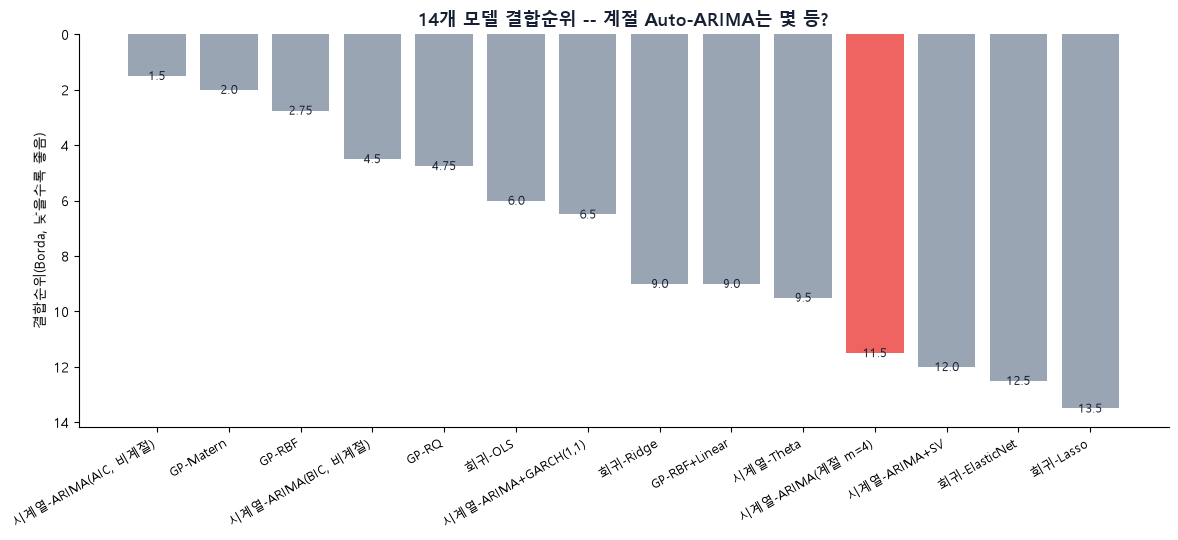

In [5]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

sorted_rank = combined["평균 순위"].sort_values()
colors = ["#EF6461" if ("계절" in idx and "비계절" not in idx) else "#9AA5B4" for idx in sorted_rank.index]

fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(sorted_rank.index, sorted_rank.values, color=colors)
for bar, v in zip(bars, sorted_rank.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.15, f"{v}", ha="center", fontsize=9.5, color="#172033")
ax.set_ylabel("결합순위(Borda, 낮을수록 좋음)")
ax.set_title("14개 모델 결합순위 -- 계절 Auto-ARIMA는 몇 등?", color="#172033", fontsize=13, fontweight="bold")
ax.invert_yaxis()
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 결합순위도 11.5로 하위권(1위 비계절 Auto-ARIMA 1.5) — 3-3
결론이 세부 모델 경쟁에서도 재현된다.

### 참고: 특정 변수만의 문제인가, 전반적인 문제인가

In [6]:
rows = []
for v in COLS:
    a = err_df[(err_df["model"] == "arima_aic") & (err_df["var"] == v) & (err_df["h"] == 4)]["err_t"].abs().mean()
    s = err_df[(err_df["model"] == "arima_seasonal") & (err_df["var"] == v) & (err_df["h"] == 4)]["err_t"].abs().mean()
    rows.append({"변수": v, "비계절 h=4 |err| 평균": round(a, 4), "계절 h=4 |err| 평균": round(s, 4), "배율(계절/비계절)": round(s / a, 2)})
pervar_df = pd.DataFrame(rows).set_index("변수")
display(pervar_df)


,비계절 h=4 |err| 평균,계절 h=4 |err| 평균,배율(계절/비계절)
변수,,,
X1_l1,139.7424,139.4968,1.00
X2,0.0058,0.0069,1.18
X3_l1,262.6204,334.2560,1.27
X4,0.0328,0.0379,1.16
X5_l1,0.0538,0.0665,1.24
X6_l1,0.0097,0.0106,1.09


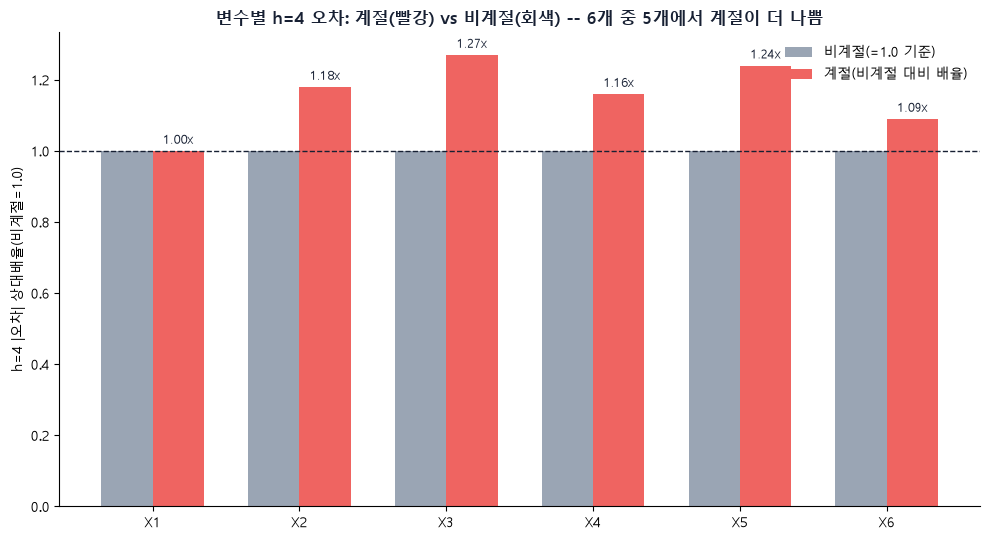

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

LABELS = {"X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
          "X4": "X4", "X5_l1": "X5", "X6_l1": "X6"}

# 변수마다 절대오차 스케일이 완전히 달라서(X1=수백 vs X2=0.005대) 원값을 그대로
# 그리면 작은 변수들이 안 보인다 -- 비계절을 1.0으로 정규화한 상대배율로 비교한다.
plot_df = pervar_df.rename(index=LABELS)
x = np.arange(len(plot_df))
width = 0.35
nonseasonal_norm = np.ones(len(plot_df))
seasonal_norm = plot_df["배율(계절/비계절)"].values

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x - width / 2, nonseasonal_norm, width, label="비계절(=1.0 기준)", color="#9AA5B4")
ax.bar(x + width / 2, seasonal_norm, width, label="계절(비계절 대비 배율)", color="#EF6461")
for i, v in enumerate(seasonal_norm):
    ax.text(i + width / 2, v + 0.02, f"{v:.2f}x", ha="center", fontsize=9, color="#172033")
ax.axhline(1.0, color="#172033", linestyle="--", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, fontsize=10)
ax.set_ylabel("h=4 |오차| 상대배율(비계절=1.0)")
ax.set_title("변수별 h=4 오차: 계절(빨강) vs 비계절(회색) -- 6개 중 5개에서 계절이 더 나쁨", color="#172033", fontsize=12.5, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 6개 중 5개 변수에서 계절 버전 오차가 더 크다(배율
1.09~1.27배) — X3만의 문제가 아니라 전반적 문제다. 계절주기(m=4)
선택이 잘못된 게 아니라, 이 거시·금융 지표들이 애초에 뚜렷한 계절성이
없어 계절 파라미터가 표본 대비 과적합만 유발하는 것으로 보인다.

### 참고: GARCH/SV를 "단독"으로 쓰면? (차분 구조 on/off, X3_l1)

GARCH/SV는 원래 자체 평균방정식으로 단독 사용도 가능하다 — 1차차분(d)·
계절차분(D, lag=4)을 켜고 끄며(2x2) X3_l1에 단독 적용한다.

In [8]:
MIN_TRAIN = 20
vals_X3 = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
var_std_X3 = vals_X3.std()
n_X3 = len(vals_X3)


def make_z_and_forecast(train, d, D):
    """d,D in {0,1}. z: GARCH/SV에 넣을 정상화된 시계열, level_forecast: 레벨 예측 복원 함수."""
    base = train[4:] - train[:-4] if D == 1 else train
    z = np.diff(base) if d == 1 else base

    def level_forecast(c, h):
        if D == 0 and d == 0:
            return c
        if D == 0 and d == 1:
            return train[-1] + h * c
        if D == 1 and d == 0:
            return train[-4 + h] + c
        base_last = train[-1] - train[-5]
        return train[-4 + h] + base_last + h * c

    return z, level_forecast


CONFIGS = [(0, 0), (1, 0), (0, 1), (1, 1)]
CONFIG_LABELS = {(0, 0): "무차분", (1, 0): "1차차분만", (0, 1): "계절차분만", (1, 1): "1차+계절차분"}

standalone_results = {}
for (d, D) in CONFIGS:
    records = []
    for origin in range(MIN_TRAIN, n_X3 - H + 1):
        train = vals_X3[:origin]
        actual = vals_X3[origin:origin + H]
        z, level_forecast = make_z_and_forecast(train, d, D)
        c = z.mean()
        fc = np.array([level_forecast(c, h) for h in range(1, H + 1)])
        err = actual - fc
        for h in range(1, H + 1):
            records.append({"origin": origin, "h": h, "err_t": err[h - 1], "fc_t": fc[h - 1], "actual_orig": actual[h - 1]})
    standalone_results[(d, D)] = pd.DataFrame(records)
print("설정별 예측 생성 완료:", [CONFIG_LABELS[c] for c in CONFIGS])


설정별 예측 생성 완료: ['무차분', '1차차분만', '계절차분만', '1차+계절차분']


In [9]:
def crps_static_sa(df, name):
    rng = rng_for(name)
    origins = sorted(df["origin"].unique())
    scores = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = df[df["origin"].isin(origins[:i])]
        test = df[df["origin"] == origins[i]]
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
            scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std_X3)
    return np.mean(scores)


def ll_static_sa(df):
    origins = sorted(df["origin"].unique())
    scores = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = df[df["origin"].isin(origins[:i])]
        sigma_h = calib.groupby("h")["err_t"].std()
        test = df[df["origin"] == origins[i]]
        for h in range(1, H + 1):
            row = test[test["h"] == h].iloc[0]
            scores.append(stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h]))
    return np.mean(scores)


def crps_ll_dynamic_sa(df, method, name):
    rng = rng_for(name)
    origins = sorted(df["origin"].unique())
    resid1_all = df[df["h"] == 1].set_index("origin")["err_t"].reindex(origins)
    crps_scores, ll_scores = [], []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = df[df["origin"].isin(origins[:i])]
        sigma_h_static = calib.groupby("h")["err_t"].std()
        test = df[df["origin"] == origins[i]]
        resid1_hist = resid1_all.iloc[:i].values
        try:
            scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
        except Exception:
            scale = 1.0
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            calib_resid_h_std = calib_resid_h / sigma_h_static[h]
            dyn_sigma_h = sigma_h_static[h] * scale
            row = test[test["h"] == h].iloc[0]
            samples = row["fc_t"] + rng.choice(calib_resid_h_std, size=N_SAMPLES, replace=True) * dyn_sigma_h
            crps_scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std_X3)
            ll_scores.append(stats.norm.logpdf(row["err_t"], loc=0, scale=dyn_sigma_h))
    return np.mean(crps_scores), np.mean(ll_scores)


rows = []
for cfg in CONFIGS:
    df = standalone_results[cfg]
    label = CONFIG_LABELS[cfg]
    crps_s = crps_static_sa(df, f"static_{cfg}")
    ll_s = ll_static_sa(df)
    rows.append({"모델": f"{label} + 정적(std)", "CRPS": round(crps_s, 4), "LL": round(ll_s, 3)})
    crps_g, ll_g = crps_ll_dynamic_sa(df, "garch11", f"garch_{cfg}")
    rows.append({"모델": f"{label} + GARCH(1,1)", "CRPS": round(crps_g, 4), "LL": round(ll_g, 3)})
    crps_sv, ll_sv = crps_ll_dynamic_sa(df, "sv", f"sv_{cfg}")
    rows.append({"모델": f"{label} + SV", "CRPS": round(crps_sv, 4), "LL": round(ll_sv, 3)})

standalone_summary = pd.DataFrame(rows).set_index("모델").sort_values("CRPS")
display(standalone_summary)
print("참고: 무변환 Auto-ARIMA(AIC) X3_l1 단독 CRPS=0.5801 (2-3 보충 표 참고)")


,CRPS,LL
모델,,
1차차분만 + 정적(std),0.5840,-7.330
"1차차분만 + GARCH(1,1)",0.5993,-7.286
1차차분만 + SV,0.6295,-9.721
계절차분만 + 정적(std),0.7430,-8.400
"계절차분만 + GARCH(1,1)",0.7451,-8.442
"무차분 + GARCH(1,1)",0.8250,-7.878
계절차분만 + SV,0.8378,-11.785
무차분 + SV,0.8413,-9.019
무차분 + 정적(std),0.8486,-8.036


참고: 무변환 Auto-ARIMA(AIC) X3_l1 단독 CRPS=0.5801 (2-3 보충 표 참고)


**해석**: **"1차차분만 + 정적(std)"이 CRPS 0.5840으로 Auto-ARIMA(AIC)의
0.5801과 거의 동급** — Auto-ARIMA가 잘 맞히는 이유의 대부분이 복잡한
AR/MA가 아니라 단순 1차 차분(추세 제거)에서 나온다는 뜻이다.

GARCH/SV는 단독으로도 도움 안 됨(0.5840→0.5993/0.6295로 악화). 계절차분은
확실히 나쁘고(0.74~0.84대), 1차+계절차분 동시 적용은 과차분으로 가장
나쁘다(0.98~1.17). GARCH/SV·계절차분 기각이 다섯 번째 독립 방식으로
재확인됐다.

## 결론

- 계절 Auto-ARIMA를 14개 모델 경쟁에 추가해도 결합순위 11.5로 하위권 —
  결론 불변.
- 3-3·4-3 두 레벨, 6개 변수 전부에서 계절 Auto-ARIMA가 비계절보다
  일관되게 나쁨 — AIC의 in-sample 선호와 정반대.
- **최종 결론**: `seasonal=False`가 맞다. 4-2의 선정(Auto-ARIMA 단일모델 /
  E3 앙상블) 유지.
- **한계**: 계절 탐색 범위(`max_P=2,max_Q=2,max_D=1`)를 넓혀도, 표본(60분기)
  부족이라는 근본 문제는 해결 안 될 것으로 보임.